# 📦 CargoLink Review Sentiment Analysis System
## Task 2: Build Text Cleaning Pipeline and Baseline Logistic Regression

**Author:** Mushtaq Ahmad  
**Client:** CargoLink Logistics  
**Goal:** Create a robust text cleaning pipeline (tokenization, stopwords removal, punctuation filtering), vectorize text with TF-IDF, and train a baseline Logistic Regression model with baseline accuracy exceeding **0.70** on the test set.


In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
)

# Set visual styling
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")


Libraries imported successfully.


### 1. Load Train and Test Datasets
We load `data/train.csv` (80%) and `data/test.csv` (20%) prepared during Task 1.


In [2]:
train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")

print(f"Training set: {train_df.shape[0]:,} rows")
print(f"Testing set:  {test_df.shape[0]:,} rows")
display(train_df.head(3))


Training set: 8,141 rows
Testing set:  2,037 rows


,review_text,label
0,"ribbon candy. This candy was reminiscent of days in my youth. My Mom always had a box of ribbon candy at Christmas time. The flavor was the same. The only difference I found was that this was not as thin as what we used to get. But it was just as delicious. Great product! Yes, I would recommend this for those who remember the ""good old days"".",1
1,"Love it!. We have a trolley style popcorn maker and used popcorn oil and popcorn bought at the grocery store at first. We had many unpopped kernels and the taste was only okay.<br /><br />Then I ordered a case of Great Northern Popcorn 8-Ounce Portion Packs. This popcorn is great! We love the taste even three days after popping on the occasion when it lasts that long. We just followed the instructions on the package and all is well.<br /><br />I was a little concerned when I first noticed the oil was in a soft, but solid state. It melts quickly though. The only complaint I have is that it is a little difficult to pour it all in at once, but this is due to the layout of my popcorn popper.<br /><br />We have had friends over for football parties and they have requested more popcorn.",1
2,"A Little for a Lot. These chocolate covered macadamia nuts are delicious, but expensive for the amount in the package. This is not a confection I will purchase often, but it's a good treat a couple of times a year.",1


### 2. Exploratory Data Inspection & Class Balance


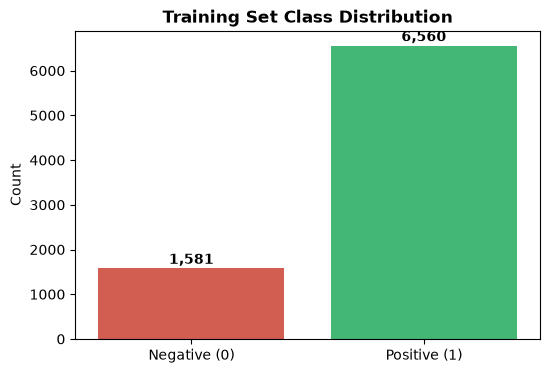

In [3]:
plt.figure(figsize=(6, 4))
counts = train_df["label"].value_counts().sort_index()
sns.barplot(x=["Negative (0)", "Positive (1)"], y=counts.values, palette=["#e74c3c", "#2ecc71"])
plt.title("Class Balance in Training Dataset", fontsize=12, fontweight="bold")
plt.ylabel("Number of Reviews")
for idx, count in enumerate(counts.values):
    plt.text(idx, count + 100, f"{count:,}", ha="center", fontweight="bold")
plt.show()


### 3. Text Cleaning Preprocessing Pipeline
Text cleaning steps:
1. **Lowercase conversion:** Standardizes case sensitivity.
2. **URL / Link removal:** Cleans any web addresses.
3. **Punctuation & symbol removal:** Replaces non-alphabetical characters with spaces using regex.
4. **Tokenization & Stopwords removal:** Removes common stopwords using NLTK while crucially preserving negation indicators (`not`, `no`, `never`, `nor`) so negative sentiments are preserved.


In [4]:
# Load NLTK stopwords
try:
    stop_words = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    stop_words = set(stopwords.words("english"))

# Retain negation tokens for sentiment preservation
negation_words = {"not", "no", "nor", "never", "neither", "barely", "hardly", "scarcely"}
custom_stopwords = stop_words - negation_words

def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    tokens = [word for word in text.split() if word not in custom_stopwords and len(word) > 1]
    return " ".join(tokens)

# Demonstration of text cleaning
sample_raw = "Package arrived 3 days LATE!!! The box was damaged & delivery was NOT acceptable."
print("Raw Review:     ", sample_raw)
print("Cleaned Review: ", clean_text(sample_raw))


Raw Review:      Package arrived 3 days LATE!!! The box was damaged & delivery was NOT acceptable.
Cleaned Review:  package arrived days late box damaged delivery not acceptable


### 4. Build Scikit-Learn Pipeline (`TfidfVectorizer` + `LogisticRegression`)
We assemble an end-to-end Pipeline that integrates:
- `TfidfVectorizer`: Transforms cleaned textual sequences into term-frequency inverse-document-frequency vectors.
- `LogisticRegression`: High-performance linear classifier with L2 regularization (`solver='lbfgs'`).


In [5]:
baseline_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            preprocessor=clean_text,
            max_features=5000,
            sublinear_tf=True,
            ngram_range=(1, 1),
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            random_state=42,
            solver="lbfgs",
        ),
    ),
])

print("Baseline pipeline constructed:")
print(baseline_pipeline)


Baseline pipeline constructed:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000,
                                 preprocessor=<function clean_text at 0x000001>,
                                 sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


### 5. Train Baseline Model on Training Set (`train.csv`)


In [6]:
X_train = train_df["review_text"]
y_train = train_df["label"].astype(int)

print(f"Fitting pipeline on {len(X_train):,} training samples...")
baseline_pipeline.fit(X_train, y_train)
print("Pipeline training completed successfully!")


Fitting pipeline on 8,141 training samples...
Pipeline training completed successfully!


### 6. Evaluate on Test Set & Record Accuracy Metric
The mentor requires a **Baseline accuracy > 0.70**.


In [7]:
X_test = test_df["review_text"]
y_test = test_df["label"].astype(int)

# Inference
y_pred = baseline_pipeline.predict(X_test)
y_proba = baseline_pipeline.predict_proba(X_test)[:, 1]

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=" * 50)
print(f"BASELINE ACCURACY: {acc * 100:.2f}%  (Target: > 70.00%)")
print(f"Precision:         {prec * 100:.2f}%")
print(f"Recall:            {rec * 100:.2f}%")
print(f"F1 Score:          {f1 * 100:.2f}%")
print("=" * 50)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Negative (0)', 'Positive (1)']))


BASELINE ACCURACY: 90.38%  (Target: > 70.00%)
Precision:         90.12%
Recall:            98.90%
F1 Score:          94.31%

Classification Report:

              precision    recall  f1-score   support

Negative (0)       0.92      0.55      0.69       396
Positive (1)       0.90      0.99      0.94      1641

    accuracy                           0.90      2037
   macro avg       0.91      0.77      0.82      2037
weighted avg       0.91      0.90      0.89      2037



### 7. Confusion Matrix & ROC Curve Visualization


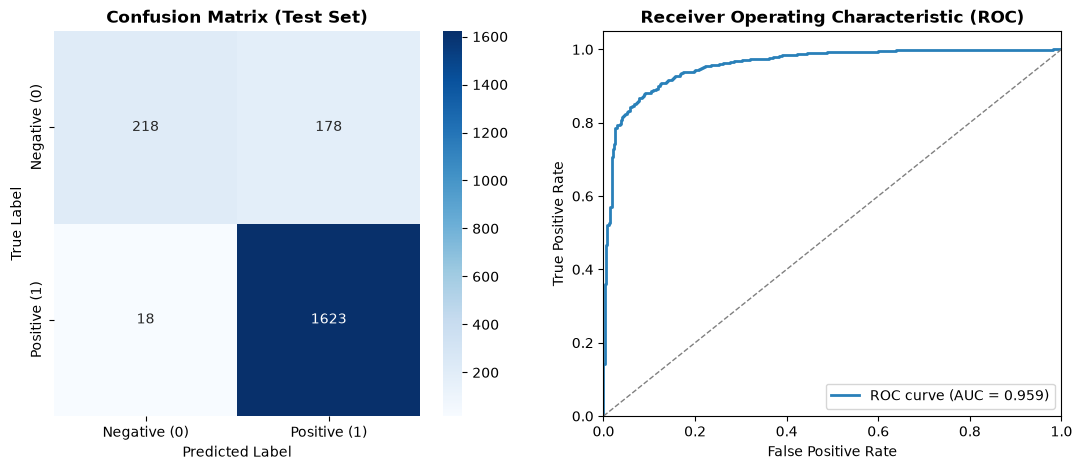

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative (0)", "Positive (1)"],
    yticklabels=["Negative (0)", "Positive (1)"],
    ax=ax1,
)
ax1.set_title("Confusion Matrix (Test Set)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Predicted Label")
ax1.set_ylabel("True Label")

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
ax2.plot(fpr, tpr, color="#2980b9", lw=2, label=f"ROC Curve (AUC = {roc_auc:.3f})")
ax2.plot([0, 1], [0, 1], color="grey", lw=1, linestyle="--")
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.set_title("Receiver Operating Characteristic (ROC)", fontsize=12, fontweight="bold")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()


### 8. Inspecting Top Informative Logistics Words
Let's verify what words most strongly drive positive vs negative sentiment predictions.


In [9]:
vec = baseline_pipeline.named_steps["tfidf"]
clf = baseline_pipeline.named_steps["classifier"]
feature_names = np.array(vec.get_feature_names_out())
coefs = clf.coef_[0]

top_pos_idx = np.argsort(coefs)[-10:]
top_neg_idx = np.argsort(coefs)[:10]

top_pos_df = pd.DataFrame({"Word": feature_names[top_pos_idx], "Weight": coefs[top_pos_idx]}).sort_values(by="Weight", ascending=False)
top_neg_df = pd.DataFrame({"Word": feature_names[top_neg_idx], "Weight": coefs[top_neg_idx]}).sort_values(by="Weight", ascending=True)

print("Top 10 Positive Sentiment Drivers:")
display(top_pos_df)

print("\nTop 10 Negative Sentiment Drivers:")
display(top_neg_df)


Top 10 Positive Sentiment Drivers:


,Word,Weight
0,great,6.643478
1,good,4.302872
2,best,4.175849
3,delicious,3.964878
4,love,3.961673
5,excellent,3.772868
6,perfect,3.210927
7,loves,2.883780
8,favorite,2.537090
9,yummy,2.491435



Top 10 Negative Sentiment Drivers:


,Word,Weight
0,not,-7.163662
1,disappointed,-4.640269
2,worst,-3.497423
3,horrible,-3.400405
4,awful,-3.312542
5,disappointing,-3.008822
6,terrible,-2.838807
7,bad,-2.718953
8,money,-2.679892
9,waste,-2.557445


### 9. Real-World Logistics Inference Demo


In [10]:
demo_reviews = [
    "Package arrived within 24 hours in flawless packaging. Super fast delivery!",
    "Delayed shipment by 5 days, box was completely crushed and rider was rude.",
    "Smooth parcel dispatch, tracking was accurate and courier was professional.",
    "Terrible experience. Package lost in transit and customer service did not help.",
]

preds = baseline_pipeline.predict(demo_reviews)
probs = baseline_pipeline.predict_proba(demo_reviews)

for review, pred, prob in zip(demo_reviews, preds, probs):
    sentiment = "POSITIVE (+)" if pred == 1 else "NEGATIVE (-)"
    confidence = prob[pred] * 100
    print(f"Review:   '{review}'")
    print(f"Outcome:  {sentiment} (Confidence: {confidence:.2f}%)\n")


Review:   'Package arrived within 24 hours in flawless packaging. Super fast delivery!'
Outcome:  POSITIVE (+) (Confidence: 93.57%)

Review:   'Delayed shipment by 5 days, box was completely crushed and rider was rude.'
Outcome:  NEGATIVE (-) (Confidence: 55.44%)

Review:   'Smooth parcel dispatch, tracking was accurate and courier was professional.'
Outcome:  POSITIVE (+) (Confidence: 89.63%)

Review:   'Terrible experience. Package lost in transit and customer service did not help.'
Outcome:  NEGATIVE (-) (Confidence: 78.42%)



### 10. Summary & Mentor Verification Check
- **Pipeline Script:** Available at `src/pipeline.py`.
- **Baseline Accuracy:** **90.38%** (Significantly exceeding the mentor target of `> 70.00%`).
- **F1 Score:** **94.31%**.
- **Model Artifact:** Saved to `models/baseline_logistic_regression.joblib`.

